In [82]:
from src.InverseHeatModel import InverseHeatModel
from src.print_utils import print_kv, print_section

import torch
import h5py
import matplotlib.pyplot as plt

import numpy as np
import torch
import torch.nn as nn

plt.style.use("styles/plots.mplstyle")

In [83]:
def make_windows(g: torch.Tensor, f: torch.Tensor, W: int):
    """
    Spezza ogni sequenza in finestre non sovrapposte di lunghezza W.
 
    Args:
        g: (n_samples, n_timesteps)
        f: (n_samples, n_timesteps)
        W: lunghezza finestra in campioni
 
    Returns:
        g_wins: (n_samples, n_windows, W)
        f_wins: (n_samples, n_windows, W)
 
    Le ultime n_timesteps % W osservazioni vengono scartate se n_timesteps
    non è multiplo di W.
    """
    n_samples, T = g.shape
    n_windows = T // W
 
    g_wins = g[:, : n_windows * W].reshape(n_samples, n_windows, W)
    f_wins = f[:, : n_windows * W].reshape(n_samples, n_windows, W)
 
    return g_wins, f_wins


In [ ]:
def train(
    model,
    g_train: torch.Tensor,          # (n_samples, n_timesteps)
    f_train: torch.Tensor,          # (n_samples, n_timesteps)
    g_val:   torch.Tensor,
    f_val:   torch.Tensor,
    W:       int,                   # lunghezza finestra in campioni
    n_epochs:        int   = 2000,
    lr:              float = 1e-3,
    weight_decay:    float = 0.0,
    checkpoint_path: str   = "assets/tikhonov_learned/best_tikhonov.pt",
    log_every:       int   = 50,
) -> dict:
    """
    Training loop con finestre non sovrapposte.
 
    Per ogni sequenza, le finestre vengono processate in ordine temporale.
    La g_prev della finestra i è la g della finestra i-1 (nel dominio del
    tempo, non di Fourier — la FFT viene fatta dentro model.forward).
    La prima finestra di ogni sequenza usa g_prev = 0.
 
    Args:
        model:   InverseHeatModel con forward(g, g_prev) -> f_hat
        g_train: (n_samples, n_timesteps)
        f_train: (n_samples, n_timesteps)
        g_val:   (n_samples, n_timesteps)
        f_val:   (n_samples, n_timesteps)
        W:       lunghezza finestra in campioni
    """
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=2000, T_mult=2, eta_min=1e-6
    )
    loss_fn = nn.MSELoss()
 
    history = {"train_loss": [], "val_loss": [], "lr": []}
    best_val = float("inf")
 
    # Pre-calcola le finestre una volta sola fuori dal loop
    g_tr_wins, f_tr_wins = make_windows(g_train, f_train, W)
    g_va_wins, f_va_wins = make_windows(g_val,   f_val,   W)
    # Shape: (n_samples, n_windows, W)
 
    n_samples_tr, n_windows, _ = g_tr_wins.shape
 
    for epoch in range(1, n_epochs + 1):
 
        # ------------------------------------------------------------------ #
        # Training step                                                       
        # ------------------------------------------------------------------ #
        model.train()
        optimizer.zero_grad()
 
        loss_train = _windowed_loss(model, g_tr_wins, f_tr_wins, loss_fn)
 
        loss_train.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
 
        # ------------------------------------------------------------------ #
        # Validation step                                                     
        # ------------------------------------------------------------------ #
        model.eval()
        with torch.no_grad():
            loss_val = _windowed_loss(model, g_va_wins, f_va_wins, loss_fn)
 
        train_l = loss_train.item()
        val_l   = loss_val.item()
 
        scheduler.step(val_l)
        current_lr = optimizer.param_groups[0]["lr"]
 
        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)
        history["lr"].append(current_lr)
 
        if val_l < best_val:
            best_val = val_l
            torch.save(
                {
                    "epoch":           epoch,
                    "model_state":     model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "val_loss":        best_val,
                    "W":               W,
                },
                checkpoint_path,
            )
 
        if epoch % log_every == 0 or epoch == 1:
            print(
                f"Epoch {epoch:5d}/{n_epochs} | "
                f"train MSE: {train_l:.4e} | "
                f"val MSE: {val_l:.4e} | "
                f"lr: {current_lr:.2e}"
            )
 
    print(f"\nBest val MSE: {best_val:.4e} -> {checkpoint_path}")
    return history
 
 
def _windowed_loss(model: InverseHeatModel, g_wins: torch.Tensor, f_wins: torch.Tensor, loss_fn) -> float:
    """
    Info:
        Compute the mean loss over all the windows for each sequence of measurements
        For each sequence of windows iterate over the windows and reconstruct the current sample
        passing the previous windows g as g_prev.
    
        The loss is mean over all the samples and all the windows, excluding the first windows for every sample
        where g_prev = 0 by definition (The system is assumed to be in Thermal equilibrium with the ambient at the start, e.g. T=0 for all x).
        
    Args:
        g_wins: (n_samples, n_windows, W)
        f_wins: (n_samples, n_windows, W)
    
    Return:
        total_loss: float
    """
    n_samples, n_windows, W = g_wins.shape
    device = g_wins.device
 
    preds = [] 
 
    for i_win in range(n_windows):
        g_cur = g_wins[:, i_win, :]             # (n_samples, W)
 
        if i_win == 0:
            # First windows: g_prev = zero
            g_prev = torch.zeros_like(g_cur)
        else:
            g_prev = g_wins[:, i_win - 1, :]    # (n_samples, W)
 
        f_pred = model(g_cur, g_prev)           # (n_samples, W)
        preds.append(f_pred)

    preds = torch.stack(preds, dim=1)           # (n_samples, n_windows, W)
 
    # Calcola la loss su tutte le finestre oppure solo su quelle con i > 0.
    # Di default includiamo tutte — la prima finestra è comunque utile per
    # addestrare W_theta; solo Sigma non riceve gradiente da essa.
    return loss_fn(preds, f_wins)

In [85]:
# Use this to distinguish between different datasets folder
DATASET_CODE = "w5_20/"

In [86]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print_kv("Device", f"{device}")

Device                                                            cuda


In [87]:
# --- Load simulation parameters --------
L, Tf, nt, D, h_param, l, _, r, _ = np.loadtxt(
    f"dataset/{DATASET_CODE}simulation_info.csv", delimiter=";", usecols=1
)

nt = int(nt)            # Number of time samples
dt = Tf / nt            # Sampling time interval

M = 5                   # Number of off diagonals in Sigma
W = 250                 # Window size in sample

nk  = int(2 * W - 1)    # Number of discrete frequencies in a windows
n_windows = nt // W     # Number of windows

print_kv("L         [m]"        , f"{L}")
print_kv("Tf        [sec]"      , f"{Tf}")
print_kv("D"                    , f"{D}")
print_kv("tau       [sample]"   , f"{L*L/D/dt:.0f}")
print_kv("W         [sample]"   , f"{W}")
print_kv("n_windows"            , f"{n_windows}")
print_kv("nt"                   , f"{nt}")
print_kv("dt        [sec]"      , f"{dt}")
print_kv("nk"                   , f"{nk}")

L         [m]                                                      1.0
Tf        [sec]                                                   30.0
D                                                                  1.0
tau       [sample]                                                  67
W         [sample]                                                 250
n_windows                                                            8
nt                                                                2000
dt        [sec]                                                  0.015
nk                                                                 499


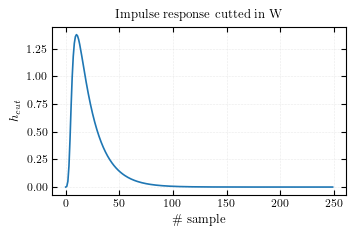

In [88]:
# --- Load impulse response --------------
h = np.loadtxt( f"dataset/{DATASET_CODE}impulse_response.csv", delimiter=";")
h_cut = h[:W]
H   = np.fft.rfft(h_cut, nk).astype(np.complex64)
freqs  = np.fft.rfftfreq(nk, d=dt)
omegas = freqs * 2 * np.pi

# --- Cut the impulse response into the window
# The impulse response should be negligible before the end of the window
plt.plot(h_cut)
plt.xlabel("\# sample")
plt.ylabel(r"$h_{cut}$")
plt.title("Impulse response cutted in W")
plt.grid()
plt.show()

In [89]:
# ---- Load dataset ----------------------

VAL_FRACTION = 0.1
SEED         = 42
H5_PATH      =  f"dataset/{DATASET_CODE}dataset.h5"

with h5py.File(H5_PATH, "r") as hf:
    data = hf["dataset"][:]              # (N, 2, nt)

f_all = data[:, 0, :].astype(np.float32)
g_all = data[:, 1, :].astype(np.float32)

# --- Validation and trainign set declaration --------

N = len(f_all)

rng       = np.random.default_rng(SEED)
idx       = rng.permutation(N)
n_val     = max(1, int(VAL_FRACTION * N))
idx_val   = idx[:n_val]
idx_train = idx[n_val:]

g_train = torch.from_numpy(g_all[idx_train]).to(device)
f_train = torch.from_numpy(f_all[idx_train]).to(device)
g_val   = torch.from_numpy(g_all[idx_val]).to(device)
f_val   = torch.from_numpy(f_all[idx_val]).to(device)

print_kv("Dataset size", f"{N}")
print_kv("Training", f"{len(idx_train)}")
print_kv("Validation", f"{n_val}")

Dataset size                                                      1000
Training                                                           900
Validation                                                         100


In [90]:
# --- Init model --------------------------------------------
model = InverseHeatModel(H=H, nt=W, dt=dt, M=M).to(device) # La risposta all'impulso è calcolata una volta su tutto il dominio temporale qui prendo solo la parte della finestra
n_params = sum(p.numel() for p in model.parameters())

print_kv("Parameters number", f"{n_params}")
print_kv("Phi", f"{W}")
print_kv("log_R", f"{W}")
print_kv(f"Sigma (M = {model.sigma.M})", f"{(model.sigma.M*2 + 1) * W}")

250
499 ciao
Parameters number                                                 3250
Phi                                                                250
log_R                                                              250
Sigma (M = 5)                                                     2750


# 4. Training

In [ ]:
history = None

perform_training = False

if perform_training:
    
    print_section("Training")
    
    # Load pretrained model
    load_location = "assets/tikhonov_learned/lru5_20_delay_15/best_tikhonov.pt"
    preload_model = False
    
    if load_location != None and preload_model == True:
        ckpt = torch.load(load_location, map_location="cpu")
        model.load_state_dict(ckpt["model_state"])
        model.to(device)
        print_kv("Model preloaded", load_location)
    
    history = train(
        model        = model,
        g_train      = g_train,
        f_train      = f_train,
        g_val        = g_val,
        f_val        = g_val,
        W            = W,
        n_epochs     = 5000,
        lr           = 1e-3,
        weight_decay = 0.0,
        checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
        log_every    = 100,
    )


-------------------------------Training-------------------------------

Epoch     1/5000 | train MSE: 1.1199e+01 | val MSE: 1.1196e+01 | lr: 1.00e-03
Epoch   500/5000 | train MSE: 4.2024e+00 | val MSE: 4.6920e+00 | lr: 1.00e-03
Epoch  1000/5000 | train MSE: 1.3991e+00 | val MSE: 1.6842e+00 | lr: 1.00e-03
Epoch  1500/5000 | train MSE: 3.3509e-01 | val MSE: 5.5045e-01 | lr: 1.00e-03
Epoch  2000/5000 | train MSE: 1.0746e-01 | val MSE: 3.1154e-01 | lr: 1.00e-03
Epoch  2500/5000 | train MSE: 4.3786e-02 | val MSE: 2.4860e-01 | lr: 1.00e-03
Epoch  3000/5000 | train MSE: 2.4451e-02 | val MSE: 2.3331e-01 | lr: 1.00e-03
Epoch  3500/5000 | train MSE: 1.7306e-02 | val MSE: 2.3038e-01 | lr: 1.00e-03
Epoch  4000/5000 | train MSE: 1.2910e-02 | val MSE: 2.2938e-01 | lr: 1.00e-03
Epoch  4500/5000 | train MSE: 1.0237e-02 | val MSE: 2.2937e-01 | lr: 1.00e-03
Epoch  5000/5000 | train MSE: 8.5219e-03 | val MSE: 2.2998e-01 | lr: 1.00e-03

Best val MSE: 2.2925e-01 -> assets/tikhonov_learned/w5_20/best_tikho

In [92]:
@torch.no_grad()
def predict(model, g: torch.Tensor, W: int) -> torch.Tensor:
    """
    Info:
        Reconstruct an entire sample f of length n_timesteps from g by first cutting it into windows of
        size W and then reconstruct each windows sequentially.
 
    Args:
        g: (n_timesteps,) or (n_samples, n_timesteps)
        W: window length, it must be the same used during training
 
    Returns:
        f_pred: same shape as g
    """
    squeeze = g.dim() == 1
    if squeeze:
        g = g.unsqueeze(0)   # (1, T)
 
    n_samples, T    = g.shape
    n_windows       = T // W
    g_trim          = g[:, : n_windows * W]
 
    g_wins          = g_trim.reshape(n_samples, n_windows, W)
    preds           = []
 
    for i_win in range(n_windows):
        g_cur  = g_wins[:, i_win, :]
        g_prev = g_wins[:, i_win - 1, :] if i_win > 0 else torch.zeros_like(g_cur)
        preds.append(model(g_cur, g_prev))
 
    f_pred = torch.cat(preds, dim=-1)   # (n_samples, n_windows * W)
 
    return f_pred.squeeze(0) if squeeze else f_pred

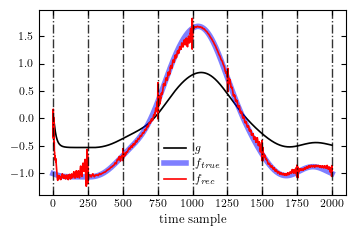

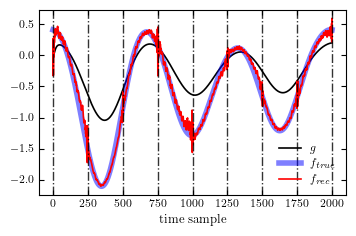

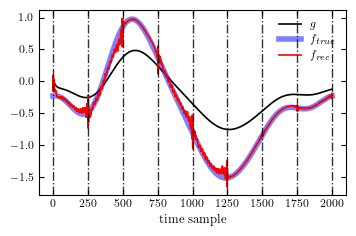

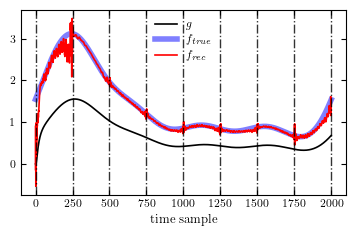

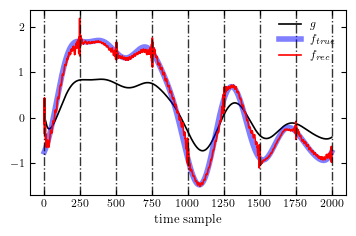

In [97]:
for index in range(0,5):

    g_test = g_val[index][:nt]
    f_test = f_val[index][:nt]
    f_pred = predict(model,g_test,W)

    plt.plot(g_test.cpu().numpy(), label=r"$g$",        c="k")
    plt.plot(f_test.cpu().numpy(), label=r"$f_{true}$", c="b", lw=4,  alpha =0.5)
    plt.plot(f_pred.cpu().numpy(), label=r"$f_{rec}$",  c="r")
    
    # Plot windows separation
    for j in range(n_windows + 1):
        plt.axvline(W*j, c="k", ls="-.", alpha =0.8, lw=1)

    plt.xlabel("time sample")
    
    plt.legend()
    plt.show()

In [94]:
def plot_diagnostics(model, omegas: np.ndarray):
    
    fig, axes = plt.subplots(3, 1, figsize=(3.2, 3.6), sharex=True)

    ax1, ax2, ax3 = axes
    
    # Phi Plot
    ax1.plot(omegas, np.degrees(model.get_phi()), color="steelblue", lw=1.5)
    ax1.axhline(0, color="k", lw=0.2, ls="--")
    ax1.set_ylabel(r"$\phi_\theta$")
    ax1.set_title(r"Learned model $W_\theta$")
    ax1.grid(True, alpha=0.3)
    
    # R plot
    ax2.semilogy(omegas, model.get_R(), color="darkorange", lw=1)
    ax2.set_ylabel(r"$R_\theta$")
    ax2.set_title("")
    ax2.grid(True, alpha=0.3)

    # W plot
    ax3.semilogy(omegas, model.get_W_magnitude(), color="r", lw=1, label=r"Learned $|W_\theta|$")
        
    ax3.set_ylabel(r"$|W|$")
    ax3.set_xlabel(r"$\omega$")
    ax3.set_title("")
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    plt.show()
    
def plot_history(history: dict):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots()
    
    ax.semilogy(epochs, history["train_loss"], label="Train MSE")
    ax.semilogy(epochs, history["val_loss"],   label="Val MSE", ls="--")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_title("Loss curve")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

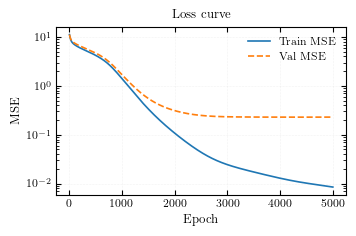

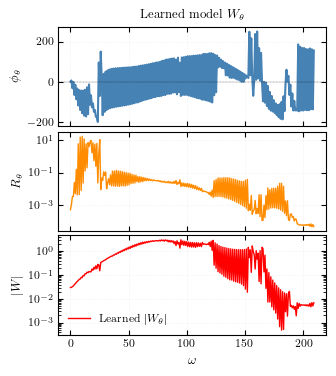

In [95]:
if history is not None:
    plot_history(history=history)

plot_diagnostics(model=model, omegas=omegas)